# 02 · Planteamiento, muestreo y estadística descriptiva

**Proyecto Unidad 2 — Inferencia estadística aplicada a un problema de Ciencia de Datos**
**Tema:** Deserción (*churn*) de clientes de un banco europeo

> 📘 Si algún término no te queda claro, búscalo en `00_aprende_desde_cero.ipynb` (tiene un glosario al final).

Este cuaderno cubre los apartados obligatorios **1, 2 y 3** del proyecto:

1. Planteamiento del problema
2. Identificación de población y muestra
3. Recolección y descripción de datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
poblacion = pd.read_csv("../data/processed/poblacion_clientes.csv")
N = len(poblacion)
print("Tamaño de la población N:", N)

Tamaño de la población N: 10000


---
## 1. Planteamiento del problema

### ¿Qué problema se investiga?
La **deserción de clientes** (*churn*): clientes que cierran su cuenta y se van a otro banco. Para un banco, cada cliente que se va se lleva sus depósitos (dinero que el banco presta y del que obtiene ganancias) y las comisiones de sus productos.

### ¿Por qué es relevante?
- En la industria se suele citar que **conseguir un cliente nuevo cuesta varias veces más que conservar uno**. Saber cuántos se van y quiénes ayuda a gastar mejor el presupuesto de retención.
- La banca europea es un mercado muy competido, con bancos digitales que facilitan cambiarse de banco.
- Desde Ingeniería en Sistemas, es un problema típico de ciencia de datos: **los datos existen en los sistemas del banco, pero hay que analizarlos correctamente para tomar decisiones**.

### ¿Qué se quiere conocer? (preguntas de investigación)

| # | Pregunta | Símbolo | En palabras |
|---|---|---|---|
| P1 | ¿Qué porcentaje de los clientes abandona el banco? | $p$ | Un porcentaje |
| P2 | ¿Cuánto dinero tienen, en promedio, los clientes que se van? | $\mu$ (se lee "miu") | Un promedio |
| P3 | ¿Cuánto más se van los clientes **inactivos** (que casi no usan su cuenta) que los **activos**? | $p_1 - p_2$ | La resta de dos porcentajes |
| P4 | ¿Cuántos años mayores son, en promedio, los que se van comparados con los que se quedan? | $\mu_1 - \mu_2$ | La resta de dos promedios |

> Cada pregunta busca un **parámetro**: un número que describe a **todo el grupo de clientes** (por ejemplo, el verdadero porcentaje que se va). Como no revisaremos a todos, ese número lo vamos a **estimar** (calcular de forma aproximada y con fundamento) usando una muestra. *(Repaso: cuaderno 00, nivel 1.)*

### ¿Cuál es la población de interés?
**Los 10,000 clientes de la cartera del banco en Francia, Alemania y España** registrados en el dataset.

---
## 2. Identificación de población y muestra

### 2.1 ¿Por qué tomar una muestra si tenemos a los 10,000 clientes?

En un banco real, **confirmar** que un cliente abandonó (y no que sólo dejó de usar su cuenta) exige revisar su expediente: movimientos, cierre de productos, transferencias de nómina. Revisar los 10,000 expedientes cuesta tiempo y dinero. Un estudio por **muestra aleatoria** permite estimar los parámetros revisando sólo una parte, con un margen de error conocido.

> **Ventaja para este proyecto:** como el dataset contiene a toda la población, al final (cuaderno 03) se puede **comprobar** si los intervalos de confianza capturaron los valores reales. Esos valores reales **no se usan para estimar**: sólo para validar el método.

### 2.2 Tamaño de la muestra

La pregunta principal es una **proporción** (P1), así que se usa la fórmula del tamaño de muestra para una proporción:

$$n_0 = \frac{z^2 \cdot p(1-p)}{E^2}$$

| Símbolo | ¿Qué es? | Valor elegido | ¿Por qué ese valor? |
|---|---|---|---|
| $n_0$ | Cuántos clientes revisar (si el banco tuviera muchísimos clientes) | se calcula | — |
| $z$ | "Cuántos brincos" sumar y restar para acertar el 95 % de las veces (cuaderno 00, nivel 3) | 1.96 | Corresponde a 95 % de confianza |
| $p$ | Porcentaje de abandono que esperamos encontrar | 0.5 (50 %) | Antes de empezar no lo sabemos; 0.5 es la opción **más prudente**, porque es la que pide revisar más clientes |
| $E$ | Margen de error: cuánto aceptamos equivocarnos hacia arriba o hacia abajo | 0.03 (±3 puntos %) | Suficiente para planear una campaña; ±2 puntos casi duplicaría el trabajo |

Como el banco tiene **un número limitado de clientes** (10,000), se aplica una corrección que reduce un poco cuántos hay que revisar:

$$n = \frac{n_0}{1 + \dfrac{n_0 - 1}{N}}$$

donde $N$ = 10,000 es el tamaño de la población. **Idea intuitiva:** si la población es pequeña, cada cliente revisado representa una parte mayor del total, así que se necesitan menos.

In [3]:
z = stats.norm.ppf(0.975)
p_supuesta = 0.5
margen_deseado = 0.03

n_inicial = z ** 2 * p_supuesta * (1 - p_supuesta) / margen_deseado ** 2
n_corregido = n_inicial / (1 + (n_inicial - 1) / N)
n = 1000

print("z:", z)
print("n0 (población infinita):", n_inicial)
print("n corregido (población de 10,000):", n_corregido)
print("n elegido:", n)
print("Fracción de muestreo n/N:", n / N)

z: 1.959963984540054
n0 (población infinita): 1067.0718946372572
n corregido (población de 10,000): 964.2734158941912
n elegido: 1000
Fracción de muestreo n/N: 0.1


📌 **Decisión: n = 1,000 clientes.** El mínimo calculado es ≈ 965; se redondea a 1,000 para tener un número fácil de comunicar y un pequeño colchón para las preguntas que dividen la muestra en grupos (P3 y P4).

⚠️ La muestra es el **10 % de todos los clientes**. Cuando se revisa más del 5 % del total, los resultados se ajustan con una pequeña corrección (como probar una cucharada de un tazón pequeño: ya conoces buena parte del tazón). Se explica en el cuaderno 03.

### 2.3 Método de selección

📌 **Decisión: Muestreo Aleatorio Simple (MAS) sin reemplazo**, con semilla fija **2026**.

- **Aleatorio simple:** la computadora **sortea** a los clientes, y cada uno de los 10,000 tiene **la misma oportunidad** de salir (1,000 / 10,000 = 10 %). Así nadie elige a conveniencia y los resultados no se inclinan hacia ningún tipo de cliente (no hay **sesgo**). Es "revolver la sopa" antes de probarla.
- **Sin reemplazo:** un cliente no puede salir dos veces.
- **Semilla fija:** el sorteo de la computadora parte de un número inicial llamado **semilla**. Si se usa siempre el mismo (2026), cualquiera puede repetir el sorteo y obtener **exactamente la misma muestra**.
- Se descartó tomar "los primeros 1,000 del archivo", porque el orden del archivo podría tener algún patrón (por ejemplo, por fecha de alta).

### 2.4 Criterios de inclusión y exclusión

| Inclusión | Exclusión |
|---|---|
| Cliente mayor de edad (≥ 18 años) | Registros duplicados |
| Estatus de abandono conocido | Registros con datos imposibles |
| Cliente de Francia, Alemania o España | Datos personales innecesarios (apellido) |

En el cuaderno 01 se comprobó que los 10,000 clientes cumplen los criterios de inclusión y que no hay registros para excluir.

In [4]:
generador = np.random.default_rng(2026)
posiciones = generador.choice(N, size=n, replace=False)
muestra = poblacion.iloc[posiciones]
muestra = muestra.reset_index(drop=True)
print("Clientes en la muestra:", len(muestra))
print("¿Algún cliente repetido?:", muestra["id_cliente"].duplicated().any())

Clientes en la muestra: 1000
¿Algún cliente repetido?: False


In [5]:
muestra.head()

,id_cliente,score_crediticio,pais,genero,edad,antiguedad,saldo,num_productos,tarjeta_credito,miembro_activo,salario_estimado,abandono,grupo_edad
0,15675256,555,España,Hombre,33,5,127343.40,1,0,1,121789.30,0,30-39
1,15653780,621,Francia,Mujer,43,5,0.00,1,1,1,47578.45,0,40-49
2,15711572,705,Alemania,Mujer,31,9,110941.93,2,1,0,163484.80,0,30-39
3,15604304,539,Alemania,Mujer,34,4,91622.42,1,1,1,136603.42,0,30-39
4,15724648,725,Francia,Hombre,26,6,98684.15,1,0,0,133720.57,0,18-29


### 2.5 ¿La muestra se parece a la población?

Si el sorteo salió bien, la muestra debería tener **casi los mismos porcentajes** que el total de clientes: más o menos la misma proporción de franceses, de mujeres, de clientes activos, etc. Se revisa con la **prueba ji cuadrada** (se escribe χ²), que responde una sola pregunta: *¿las diferencias que veo son normales para un sorteo, o son sospechosamente grandes?*

Su resultado es el **p-valor**:
- **Mayor a 0.05** → las diferencias son normales; la muestra está bien.
- **Menor a 0.05** → las diferencias son raras; habría que revisar el sorteo.

*(Ejemplo: 6 águilas en 10 volados es normal; 10 de 10 es sospechoso. Cuaderno 00, nivel 4.)*

> No se compara la tasa de abandono porque es justamente lo que queremos estimar.

#### Planteamiento de la prueba (se aplica a cada una de las 5 variables)

- **H0:** la distribución de la variable en la muestra es igual a la de la población.
- **H1:** la distribución de la variable en la muestra es distinta a la de la población.
- **Nivel de significancia:** α = 0.05.

**Supuestos de la prueba χ² de bondad de ajuste:**
1. La muestra es aleatoria: se cumple (muestreo aleatorio simple).
2. Cada cliente cae en una sola categoría: se cumple.
3. La frecuencia esperada es de al menos 5 en cada categoría: se imprime en cada celda.

**Tamaño del efecto:** w de Cohen = √(χ² / n). Valores de referencia: 0.1 pequeño, 0.3 mediano, 0.5 grande.

In [6]:
# País
proporcion_poblacion = poblacion["pais"].value_counts(normalize=True)
proporcion_poblacion = proporcion_poblacion.sort_index()
conteo_muestra = muestra["pais"].value_counts()
conteo_muestra = conteo_muestra.sort_index()
esperado = proporcion_poblacion * n

# supuesto: frecuencia esperada de al menos 5 en cada categoría
print("Frecuencia esperada mínima:", esperado.min())

prueba = stats.chisquare(conteo_muestra, esperado)
w_cohen = np.sqrt(prueba.statistic / n)
print("Estadístico χ²:", prueba.statistic)
print("p-valor:", prueba.pvalue)
print("Tamaño del efecto (w de Cohen):", w_cohen)

comparacion = pd.DataFrame({"% población": proporcion_poblacion * 100,
                            "% muestra": conteo_muestra / n * 100})
comparacion

Frecuencia esperada mínima:

 247.70000000000002
Estadístico χ²: 4.279487133889545
p-valor: 0.11768501748133667
Tamaño del efecto (w de Cohen): 0.06541778912413308


,% población,% muestra
pais,,
Alemania,25.09,27.6
España,24.77,22.7
Francia,50.14,49.7


In [7]:
# Género
proporcion_poblacion = poblacion["genero"].value_counts(normalize=True)
proporcion_poblacion = proporcion_poblacion.sort_index()
conteo_muestra = muestra["genero"].value_counts()
conteo_muestra = conteo_muestra.sort_index()
esperado = proporcion_poblacion * n

# supuesto: frecuencia esperada de al menos 5 en cada categoría
print("Frecuencia esperada mínima:", esperado.min())

prueba = stats.chisquare(conteo_muestra, esperado)
w_cohen = np.sqrt(prueba.statistic / n)
print("Estadístico χ²:", prueba.statistic)
print("p-valor:", prueba.pvalue)
print("Tamaño del efecto (w de Cohen):", w_cohen)

comparacion = pd.DataFrame({"% población": proporcion_poblacion * 100,
                            "% muestra": conteo_muestra / n * 100})
comparacion

Frecuencia esperada mínima: 454.29999999999995
Estadístico χ²: 0.04392696410102154
p-valor: 0.8339895546897045
Tamaño del efecto (w de Cohen): 0.006627742006220636


,% población,% muestra
genero,,
Hombre,54.57,54.9
Mujer,45.43,45.1


In [8]:
# Actividad (0 = inactivo, 1 = activo)
proporcion_poblacion = poblacion["miembro_activo"].value_counts(normalize=True)
proporcion_poblacion = proporcion_poblacion.sort_index()
conteo_muestra = muestra["miembro_activo"].value_counts()
conteo_muestra = conteo_muestra.sort_index()
esperado = proporcion_poblacion * n

# supuesto: frecuencia esperada de al menos 5 en cada categoría
print("Frecuencia esperada mínima:", esperado.min())

prueba = stats.chisquare(conteo_muestra, esperado)
w_cohen = np.sqrt(prueba.statistic / n)
print("Estadístico χ²:", prueba.statistic)
print("p-valor:", prueba.pvalue)
print("Tamaño del efecto (w de Cohen):", w_cohen)

comparacion = pd.DataFrame({"% población": proporcion_poblacion * 100,
                            "% muestra": conteo_muestra / n * 100})
comparacion

Frecuencia esperada mínima:

 484.9
Estadístico χ²: 1.9201912912652817
p-valor: 0.16583557404670027
Tamaño del efecto (w de Cohen): 0.043819987348985866


,% población,% muestra
miembro_activo,,
0,48.49,46.3
1,51.51,53.7


In [9]:
# Número de productos
proporcion_poblacion = poblacion["num_productos"].value_counts(normalize=True)
proporcion_poblacion = proporcion_poblacion.sort_index()
conteo_muestra = muestra["num_productos"].value_counts()
conteo_muestra = conteo_muestra.sort_index()
esperado = proporcion_poblacion * n

# supuesto: frecuencia esperada de al menos 5 en cada categoría
print("Frecuencia esperada mínima:", esperado.min())

prueba = stats.chisquare(conteo_muestra, esperado)
w_cohen = np.sqrt(prueba.statistic / n)
print("Estadístico χ²:", prueba.statistic)
print("p-valor:", prueba.pvalue)
print("Tamaño del efecto (w de Cohen):", w_cohen)

comparacion = pd.DataFrame({"% población": proporcion_poblacion * 100,
                            "% muestra": conteo_muestra / n * 100})
comparacion

Frecuencia esperada mínima: 6.0
Estadístico χ²: 2.746271510476823
p-valor: 0.4324211201596039
Tamaño del efecto (w de Cohen): 0.05240488059786821


,% población,% muestra
num_productos,,
1,50.84,50.3
2,45.90,46.1
3,2.66,2.6
4,0.60,1.0


In [10]:
# Grupo de edad
proporcion_poblacion = poblacion["grupo_edad"].value_counts(normalize=True)
proporcion_poblacion = proporcion_poblacion.sort_index()
conteo_muestra = muestra["grupo_edad"].value_counts()
conteo_muestra = conteo_muestra.sort_index()
esperado = proporcion_poblacion * n

# supuesto: frecuencia esperada de al menos 5 en cada categoría
print("Frecuencia esperada mínima:", esperado.min())

prueba = stats.chisquare(conteo_muestra, esperado)
w_cohen = np.sqrt(prueba.statistic / n)
print("Estadístico χ²:", prueba.statistic)
print("p-valor:", prueba.pvalue)
print("Tamaño del efecto (w de Cohen):", w_cohen)

comparacion = pd.DataFrame({"% población": proporcion_poblacion * 100,
                            "% muestra": conteo_muestra / n * 100})
comparacion

Frecuencia esperada mínima: 52.6
Estadístico χ²: 0.9015403973706554
p-valor: 0.9243397207456229
Tamaño del efecto (w de Cohen): 0.030025662313605265


,% población,% muestra
grupo_edad,,
18-29,16.41,15.7
30-39,43.46,43.2
40-49,26.18,27.0
50-59,8.69,9.1
60+,5.26,5.0


**Resultados:**

| Variable | χ² | p-valor | Frecuencia esperada mínima | w de Cohen | Decisión |
|---|---|---|---|---|---|
| País | 4.279 | 0.118 | 247.7 | 0.065 | No se rechaza H0 |
| Género | 0.044 | 0.834 | 454.3 | 0.007 | No se rechaza H0 |
| Actividad | 1.920 | 0.166 | 484.9 | 0.044 | No se rechaza H0 |
| Número de productos | 2.746 | 0.432 | 6.0 | 0.052 | No se rechaza H0 |
| Grupo de edad | 0.902 | 0.924 | 52.6 | 0.030 | No se rechaza H0 |

**Supuestos:** en las 5 variables la frecuencia esperada mínima es de al menos 5. La más baja es 6.0 (clientes con 4 productos), apenas por encima del límite.

**Conclusión:** No se rechaza H0 en ninguna de las 5 variables (todos los p-valores son mayores que 0.05). No hay evidencia de que la muestra tenga una distribución distinta a la de la población en país, género, actividad, número de productos y grupo de edad.

**Importancia práctica:** todos los valores de w son menores que 0.1, es decir, las diferencias entre la muestra y la población son muy pequeñas (de 0 a 2.5 puntos porcentuales).

No rechazar H0 no demuestra que las distribuciones sean idénticas. Sólo indica que las diferencias observadas son del tamaño que produce el azar del sorteo.

In [11]:
muestra.to_csv("../data/processed/muestra_clientes_n1000.csv", index=False, encoding="utf-8-sig")
muestra.to_excel("../data/processed/muestra_clientes_n1000.xlsx", index=False, sheet_name="muestra")
print("Muestra guardada en CSV y Excel, n =", len(muestra))

Muestra guardada en CSV y Excel, n = 1000


---
## 3. Recolección y descripción de datos

### 3.1 ¿Cómo se obtuvieron los datos?
- **Fuente:** dataset público *Churn Modelling* (Kaggle), con registros anonimizados de clientes de un banco en Francia, Alemania y España (ficha técnica en el cuaderno 01).
- **Revisión de calidad y preparación:** cuaderno `01_conocer_y_preparar_datos.ipynb`.
- **Selección:** muestreo aleatorio simple de 1,000 clientes (sección 2).
- **Herramientas:** Python (Pandas, NumPy, SciPy, Matplotlib) en Jupyter.

### 3.2 Variables cuantitativas

Para cada variable numérica se calculan las medidas que pide el proyecto:

| Medida | ¿Qué dice? |
|---|---|
| **Media** | El promedio: suma de valores ÷ número de valores |
| **Mediana** | El valor del centro al ordenar los datos (la mitad está por debajo) |
| **Desviación estándar** | Qué tan "regados" están los datos: cuánto se aleja, en promedio, cada valor del promedio |
| **Mínimo / Máximo** | El valor más chico y el más grande |
| **Rango** | Máximo − mínimo: qué tan amplia es la variación |

In [12]:
cuantitativas = muestra[["edad", "antiguedad", "score_crediticio", "saldo", "salario_estimado"]]
cuantitativas.describe()

,edad,antiguedad,score_crediticio,saldo,salario_estimado
count,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000
mean,39.036000,5.178000,649.47900,75457.168330,102276.909030
std,10.505287,2.941253,97.21845,63151.030765,56959.742738
min,18.000000,0.000000,350.00000,0.000000,91.750000
25%,32.000000,3.000000,579.75000,0.000000,55648.247500
50%,38.000000,5.000000,652.00000,95809.285000,105952.890000
75%,44.000000,8.000000,716.00000,128735.460000,149740.545000
max,79.000000,10.000000,850.00000,204223.030000,199753.970000


In [13]:
maximos = cuantitativas.max()
minimos = cuantitativas.min()
rango = maximos - minimos
print("Rango de cada variable:")
print(rango)

Rango de cada variable:
edad                    61.00
antiguedad              10.00
score_crediticio       500.00
saldo               204223.03
salario_estimado    199662.22
dtype: float64


**Lectura de la tabla:**
- **Edad:** la media (~39 años) es un poco mayor que la mediana: hay algunos clientes de edad avanzada que "jalan" el promedio hacia arriba.
- **Saldo:** la **mediana es mayor que la media** y el mínimo es 0: muchos clientes tienen saldo cero, lo que baja el promedio. La gráfica 3 muestra por qué.
- **Antigüedad, score y salario:** media y mediana parecidas → distribuciones bastante simétricas.

### Comparación por grupo (variables de P2 y P4)

In [14]:
grupos = muestra.groupby("abandono")
resumen_grupos = grupos[["edad", "saldo"]].agg(["count", "mean", "median", "std"])
# fila 0 = permanece, fila 1 = abandona
resumen_grupos

edad                             saldo                            \
         count       mean median       std count          mean      median   
abandono                                                                     
0          794  37.098237   36.0  9.935627   794  71278.957834   89744.540   
1          206  46.504854   46.0  9.238175   206  91561.533058  109990.445   

                        
                   std  
abandono                
0         63166.940418  
1         60592.914152

### 3.3 Variables cualitativas: frecuencias y porcentajes

- **Frecuencia:** cuántos clientes hay en cada categoría.
- **Porcentaje:** esa frecuencia dividida entre el total, × 100.

In [15]:
frecuencia_abandono = muestra["abandono"].value_counts()
frecuencia_abandono = frecuencia_abandono.sort_index()
porcentaje_abandono = frecuencia_abandono / n * 100
tabla_abandono = pd.DataFrame({"frecuencia": frecuencia_abandono, "porcentaje (%)": porcentaje_abandono})
tabla_abandono

,frecuencia,porcentaje (%)
abandono,,
0,794,79.4
1,206,20.6


In [16]:
frecuencia_miembro_activo = muestra["miembro_activo"].value_counts()
frecuencia_miembro_activo = frecuencia_miembro_activo.sort_index()
porcentaje_miembro_activo = frecuencia_miembro_activo / n * 100
tabla_miembro_activo = pd.DataFrame({"frecuencia": frecuencia_miembro_activo, "porcentaje (%)": porcentaje_miembro_activo})
tabla_miembro_activo

,frecuencia,porcentaje (%)
miembro_activo,,
0,463,46.3
1,537,53.7


In [17]:
frecuencia_pais = muestra["pais"].value_counts()
frecuencia_pais = frecuencia_pais.sort_index()
porcentaje_pais = frecuencia_pais / n * 100
tabla_pais = pd.DataFrame({"frecuencia": frecuencia_pais, "porcentaje (%)": porcentaje_pais})
tabla_pais

,frecuencia,porcentaje (%)
pais,,
Alemania,276,27.6
España,227,22.7
Francia,497,49.7


In [18]:
frecuencia_genero = muestra["genero"].value_counts()
frecuencia_genero = frecuencia_genero.sort_index()
porcentaje_genero = frecuencia_genero / n * 100
tabla_genero = pd.DataFrame({"frecuencia": frecuencia_genero, "porcentaje (%)": porcentaje_genero})
tabla_genero

,frecuencia,porcentaje (%)
genero,,
Hombre,549,54.9
Mujer,451,45.1


In [19]:
frecuencia_num_productos = muestra["num_productos"].value_counts()
frecuencia_num_productos = frecuencia_num_productos.sort_index()
porcentaje_num_productos = frecuencia_num_productos / n * 100
tabla_num_productos = pd.DataFrame({"frecuencia": frecuencia_num_productos, "porcentaje (%)": porcentaje_num_productos})
tabla_num_productos

,frecuencia,porcentaje (%)
num_productos,,
1,503,50.3
2,461,46.1
3,26,2.6
4,10,1.0


In [20]:
frecuencia_tarjeta_credito = muestra["tarjeta_credito"].value_counts()
frecuencia_tarjeta_credito = frecuencia_tarjeta_credito.sort_index()
porcentaje_tarjeta_credito = frecuencia_tarjeta_credito / n * 100
tabla_tarjeta_credito = pd.DataFrame({"frecuencia": frecuencia_tarjeta_credito, "porcentaje (%)": porcentaje_tarjeta_credito})
tabla_tarjeta_credito

,frecuencia,porcentaje (%)
tarjeta_credito,,
0,295,29.5
1,705,70.5


In [21]:
frecuencia_grupo_edad = muestra["grupo_edad"].value_counts()
frecuencia_grupo_edad = frecuencia_grupo_edad.sort_index()
porcentaje_grupo_edad = frecuencia_grupo_edad / n * 100
tabla_grupo_edad = pd.DataFrame({"frecuencia": frecuencia_grupo_edad, "porcentaje (%)": porcentaje_grupo_edad})
tabla_grupo_edad

,frecuencia,porcentaje (%)
grupo_edad,,
18-29,157,15.7
30-39,432,43.2
40-49,270,27.0
50-59,91,9.1
60+,50,5.0


### Tabla de contingencia: actividad vs. abandono (pregunta P3)

Una **tabla de contingencia** es una tabla de doble entrada: cuenta cuántos clientes hay en cada combinación (por ejemplo, "inactivo y se fue").

In [22]:
actividad = muestra["miembro_activo"].map({0: "Inactivo", 1: "Activo"})
estatus = muestra["abandono"].map({0: "Permanece", 1: "Abandona"})
pd.crosstab(actividad, estatus, margins=True, margins_name="Total")

abandono,Abandona,Permanece,Total
miembro_activo,,,
Activo,83,454,537
Inactivo,123,340,463
Total,206,794,1000


In [23]:
# porcentaje dentro de cada fila
porcentaje_fila = pd.crosstab(actividad, estatus, normalize="index")
porcentaje_fila = porcentaje_fila * 100
porcentaje_fila

abandono,Abandona,Permanece
miembro_activo,,
Activo,15.456238,84.543762
Inactivo,26.565875,73.434125


---
### 3.4 Visualizaciones

Cada gráfica se guarda en `reports/figures/` para el documento PDF y la presentación.

#### Gráfica 1 · ¿Cuántos clientes abandonan?

Permanecen: 794
Abandonan: 206


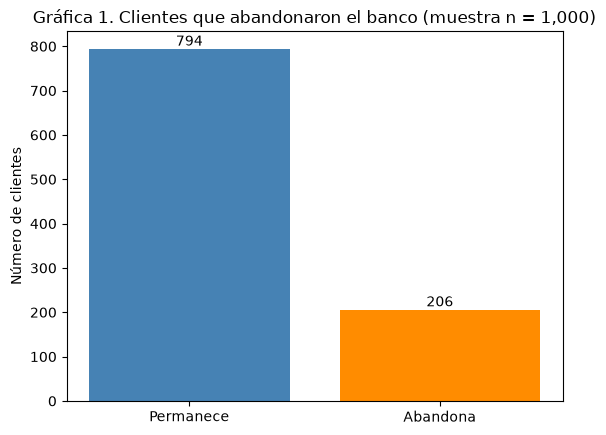

In [24]:
conteo = muestra["abandono"].value_counts()
conteo = conteo.sort_index()
print("Permanecen:", conteo[0])
print("Abandonan:", conteo[1])

barras = plt.bar(["Permanece", "Abandona"], conteo, color=["steelblue", "darkorange"])
plt.bar_label(barras)
plt.ylabel("Número de clientes")
plt.title("Gráfica 1. Clientes que abandonaron el banco (muestra n = 1,000)")
plt.savefig("../reports/figures/g1_distribucion_abandono.png", bbox_inches="tight")
plt.show()

**¿Qué aporta?** Muestra el tamaño del problema: **aproximadamente 1 de cada 5 clientes** de la muestra abandonó el banco. Ambos grupos tienen suficientes clientes para usar las fórmulas de proporciones (se necesitan al menos 10 en cada uno).

#### Gráfica 2 · Abandono según la actividad del cliente

% que abandona, inactivos: 26.565874730021598
% que abandona, activos: 15.456238361266294


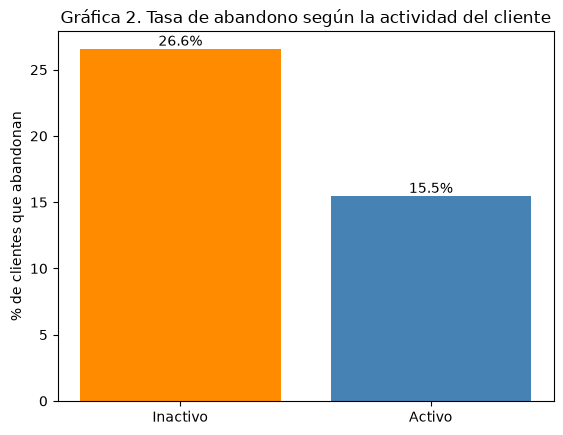

In [25]:
grupos_actividad = muestra.groupby("miembro_activo")
tasa_actividad = grupos_actividad["abandono"].mean()
tasa_actividad = tasa_actividad * 100
print("% que abandona, inactivos:", tasa_actividad[0])
print("% que abandona, activos:", tasa_actividad[1])

barras = plt.bar(["Inactivo", "Activo"], tasa_actividad, color=["darkorange", "steelblue"])
plt.bar_label(barras, fmt="%.1f%%")
plt.ylabel("% de clientes que abandonan")
plt.title("Gráfica 2. Tasa de abandono según la actividad del cliente")
plt.savefig("../reports/figures/g2_abandono_por_actividad.png", bbox_inches="tight")
plt.show()

**¿Qué aporta?** En la muestra, los clientes **inactivos abandonan bastante más** que los activos. Esta diferencia **observada en la muestra** genera la pregunta P3: ¿existe también en toda la población, o pudo ser casualidad del muestreo?

#### Gráfica 3 · Saldo de los clientes que abandonan

Media del saldo: 91561.53305825242
Mediana del saldo: 109990.445


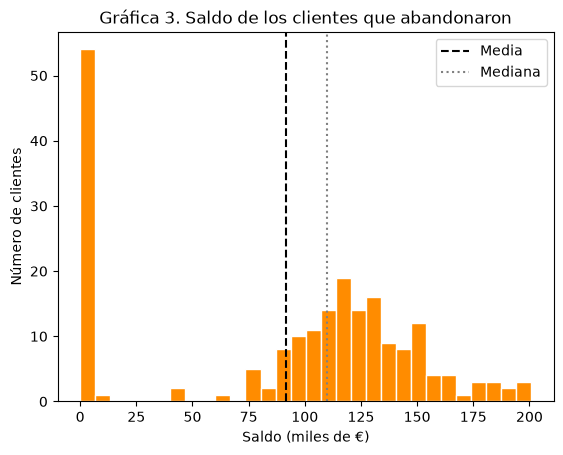

In [26]:
es_abandono = muestra["abandono"] == 1
saldo_abandona = muestra.loc[es_abandono, "saldo"]
saldo_miles = saldo_abandona / 1000
print("Media del saldo:", saldo_abandona.mean())
print("Mediana del saldo:", saldo_abandona.median())

plt.hist(saldo_miles, bins=30, color="darkorange", edgecolor="white")
plt.axvline(saldo_miles.mean(), color="black", linestyle="--", label="Media")
plt.axvline(saldo_miles.median(), color="gray", linestyle=":", label="Mediana")
plt.xlabel("Saldo (miles de €)")
plt.ylabel("Número de clientes")
plt.title("Gráfica 3. Saldo de los clientes que abandonaron")
plt.legend()
plt.savefig("../reports/figures/g3_hist_saldo_abandono.png", bbox_inches="tight")
plt.show()

In [27]:
saldo_en_cero = saldo_abandona == 0
print("% de clientes que abandonaron con saldo 0:", saldo_en_cero.mean() * 100)

% de clientes que abandonaron con saldo 0: 26.21359223300971


**¿Qué aporta?** El saldo forma **dos grupos**: una barra alta en **cero** (cuentas sin dinero) y una "campana" de clientes con saldos alrededor de 100 a 150 mil euros. Por eso:
- El **promedio** cae entre los dos grupos, así que no describe a un cliente "típico".
- Los datos **no tienen forma de campana**. Aun así se puede calcular un rango para el promedio gracias a una "ley" de la estadística, el **Teorema del Límite Central**: aunque los datos no sean una campana, **el promedio de muchas muestras sí lo es** (cuaderno 00, nivel 2; se comprueba en el cuaderno 03).

#### Gráfica 4 · Edad según abandono

Mediana de edad, permanece: 36.0
Mediana de edad, abandona: 46.0


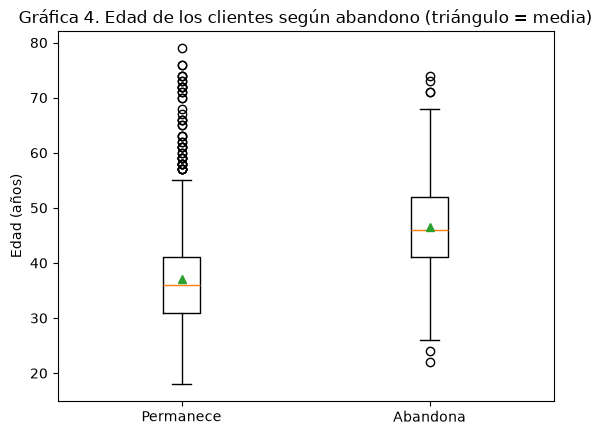

In [28]:
es_permanece = muestra["abandono"] == 0
edad_permanece = muestra.loc[es_permanece, "edad"]
edad_abandona = muestra.loc[es_abandono, "edad"]
print("Mediana de edad, permanece:", edad_permanece.median())
print("Mediana de edad, abandona:", edad_abandona.median())

plt.boxplot([edad_permanece, edad_abandona], tick_labels=["Permanece", "Abandona"], showmeans=True)
plt.ylabel("Edad (años)")
plt.title("Gráfica 4. Edad de los clientes según abandono (triángulo = media)")
plt.savefig("../reports/figures/g4_box_edad_abandono.png", bbox_inches="tight")
plt.show()

**¿Cómo se lee?** Un **diagrama de caja** resume muchos datos en un dibujo: la **caja** contiene a la mitad de los clientes que están "en medio", la **línea** dentro de la caja es la mediana (el valor de en medio), las **líneas largas** llegan hasta los valores normales más extremos y los **círculos** son casos raros. La caja de quienes abandonan está **más arriba**: los clientes que se van tienden a ser **mayores**. Motiva la pregunta P4 (diferencia de medias).

#### Gráfica 5 · Abandono por país

% que abandona por país:
pais
España      17.180617
Francia     18.108652
Alemania    27.898551
Name: abandono, dtype: float64


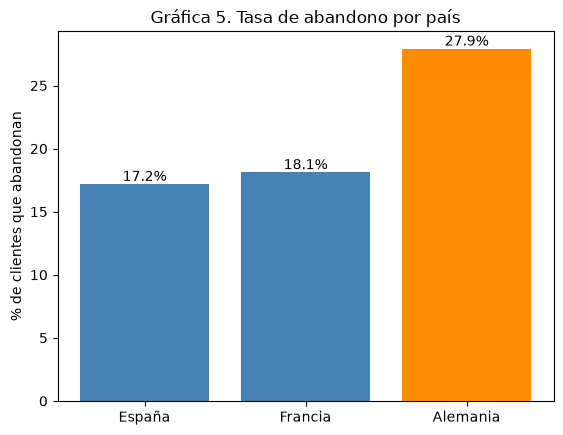

In [29]:
grupos_pais = muestra.groupby("pais")
tasa_pais = grupos_pais["abandono"].mean()
tasa_pais = tasa_pais.sort_values()
tasa_pais = tasa_pais * 100
print("% que abandona por país:")
print(tasa_pais)

barras = plt.bar(tasa_pais.index, tasa_pais, color=["steelblue", "steelblue", "darkorange"])
plt.bar_label(barras, fmt="%.1f%%")
plt.ylabel("% de clientes que abandonan")
plt.title("Gráfica 5. Tasa de abandono por país")
plt.savefig("../reports/figures/g5_abandono_por_pais.png", bbox_inches="tight")
plt.show()

**¿Qué aporta?** En la muestra, los clientes de **Alemania** abandonan **unos 10 puntos porcentuales más** que los de Francia y España (≈ 28 % contra ≈ 18 %). No es una de las cuatro preguntas formales, pero es un hallazgo importante para el banco y queda como línea de investigación (¿hay más competencia en Alemania?, ¿el servicio es distinto?).

---
## Resumen del cuaderno

- **Población:** N = 10,000 clientes. **Muestra:** n = 1,000 por muestreo aleatorio simple (semilla 2026), representativa en país, género, actividad, productos y edad.
- Aproximadamente **1 de cada 5** clientes de la muestra abandonó.
- Abandonan más los **inactivos**, los **mayores** y los clientes de **Alemania**; el saldo tiene **dos grupos** (cero y ~120 mil €).

➡️ **Siguiente cuaderno:** `03_inferencia_y_decision.ipynb`: estimación puntual, intervalos de confianza, análisis y teoría de decisión.